# BREAST CANCER WISCONSIN (DIAGNOSTIC) DATASET

## Aim
To perform Exploratory Data Analysis (EDA), data preprocessing,
70:30 training-testing split and classification using machine
learning algorithms.

## Objective
To classify breast tumour samples as Malignant or Benign
using machine learning algorithms.

## Dataset Information
- Dataset: Breast Cancer Wisconsin (Diagnostic)
- Source: UCI Machine Learning Repository
- Dataset ID: 17
- Total records: 569
- Input features: 30
- Target variable: Diagnosis
- Classification type: Binary Classification

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

print("All required libraries imported successfully!")

All required libraries imported successfully!


In [2]:
# Fetch Breast Cancer Wisconsin (Diagnostic) dataset

breast_cancer = fetch_ucirepo(id=17)

X = breast_cancer.data.features.copy()
y = breast_cancer.data.targets.copy()

print("Dataset downloaded successfully!")

Dataset downloaded successfully!


In [3]:
print("Input feature columns:")
print(X.columns.tolist())

print("\nTarget columns:")
print(y.columns.tolist())

Input feature columns:
['radius1', 'texture1', 'perimeter1', 'area1', 'smoothness1', 'compactness1', 'concavity1', 'concave_points1', 'symmetry1', 'fractal_dimension1', 'radius2', 'texture2', 'perimeter2', 'area2', 'smoothness2', 'compactness2', 'concavity2', 'concave_points2', 'symmetry2', 'fractal_dimension2', 'radius3', 'texture3', 'perimeter3', 'area3', 'smoothness3', 'compactness3', 'concavity3', 'concave_points3', 'symmetry3', 'fractal_dimension3']

Target columns:
['Diagnosis']


In [4]:
# Remove identifier column if present

id_columns = [
    col for col in X.columns
    if col.strip().lower() in ["id", "sample_code_number"]
]

if id_columns:
    X = X.drop(columns=id_columns)
    print("Removed identifier columns:", id_columns)
else:
    print("No identifier column found.")

print("\nFinal number of input features:", X.shape[1])

No identifier column found.

Final number of input features: 30


In [5]:
print("Input features:")
display(X.head())

print("\nTarget variable:")
display(y.head())

Input features:


,radius1,texture1,perimeter1,area1,smoothness1,compactness1,concavity1,concave_points1,symmetry1,fractal_dimension1,...,radius3,texture3,perimeter3,area3,smoothness3,compactness3,concavity3,concave_points3,symmetry3,fractal_dimension3
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678



Target variable:


,Diagnosis
0,M
1,M
2,M
3,M
4,M


In [6]:
print("Number of records:", X.shape[0])
print("Number of input features:", X.shape[1])
print("Number of target columns:", y.shape[1])

Number of records: 569
Number of input features: 30
Number of target columns: 1


In [7]:
# Combine features and target

df = pd.concat(
    [
        X.reset_index(drop=True),
        y.reset_index(drop=True)
    ],
    axis=1
)

print("Combined dataset:")
display(df.head())

Combined dataset:


,radius1,texture1,perimeter1,area1,smoothness1,compactness1,concavity1,concave_points1,symmetry1,fractal_dimension1,...,texture3,perimeter3,area3,smoothness3,compactness3,concavity3,concave_points3,symmetry3,fractal_dimension3,Diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,M
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,M
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,M
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,M
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,M


In [8]:
target_column = y.columns[0]

print("Target column:", target_column)

print("\nDiagnosis distribution:")
print(df[target_column].value_counts())

print("\nNumber of diagnosis classes:")
print(df[target_column].nunique())

Target column: Diagnosis

Diagnosis distribution:
Diagnosis
B    357
M    212
Name: count, dtype: int64

Number of diagnosis classes:
2


In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   radius1             569 non-null    float64
 1   texture1            569 non-null    float64
 2   perimeter1          569 non-null    float64
 3   area1               569 non-null    float64
 4   smoothness1         569 non-null    float64
 5   compactness1        569 non-null    float64
 6   concavity1          569 non-null    float64
 7   concave_points1     569 non-null    float64
 8   symmetry1           569 non-null    float64
 9   fractal_dimension1  569 non-null    float64
 10  radius2             569 non-null    float64
 11  texture2            569 non-null    float64
 12  perimeter2          569 non-null    float64
 13  area2               569 non-null    float64
 14  smoothness2         569 non-null    float64
 15  compactness2        569 non-null    float64
 16  concavity2         

In [10]:
print("Statistical summary:")
display(df.describe())

Statistical summary:


,radius1,texture1,perimeter1,area1,smoothness1,compactness1,concavity1,concave_points1,symmetry1,fractal_dimension1,...,radius3,texture3,perimeter3,area3,smoothness3,compactness3,concavity3,concave_points3,symmetry3,fractal_dimension3
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


In [11]:
print("Missing values in each column:")
print(df.isnull().sum())

print("\nTotal missing values:")
print(df.isnull().sum().sum())

Missing values in each column:
radius1               0
texture1              0
perimeter1            0
area1                 0
smoothness1           0
compactness1          0
concavity1            0
concave_points1       0
symmetry1             0
fractal_dimension1    0
radius2               0
texture2              0
perimeter2            0
area2                 0
smoothness2           0
compactness2          0
concavity2            0
concave_points2       0
symmetry2             0
fractal_dimension2    0
radius3               0
texture3              0
perimeter3            0
area3                 0
smoothness3           0
compactness3          0
concavity3            0
concave_points3       0
symmetry3             0
fractal_dimension3    0
Diagnosis             0
dtype: int64

Total missing values:
0


In [12]:
print("Number of duplicate records:", df.duplicated().sum())

Number of duplicate records: 0


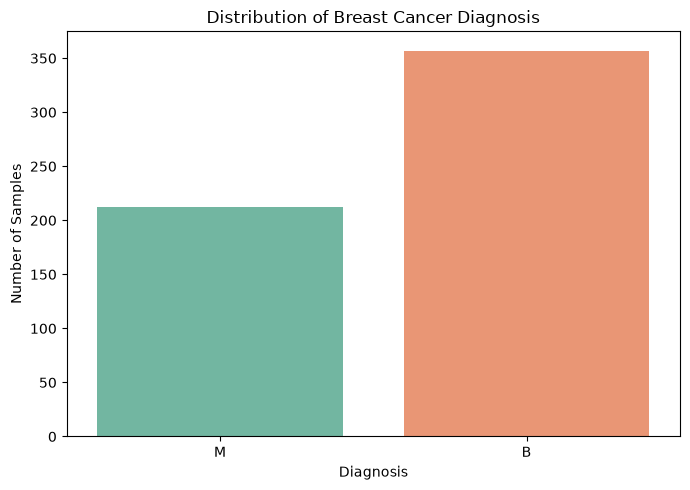

In [13]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x=target_column,
    hue=target_column,
    palette="Set2",
    legend=False
)

plt.title("Distribution of Breast Cancer Diagnosis")
plt.xlabel("Diagnosis")
plt.ylabel("Number of Samples")
plt.tight_layout()
plt.show()

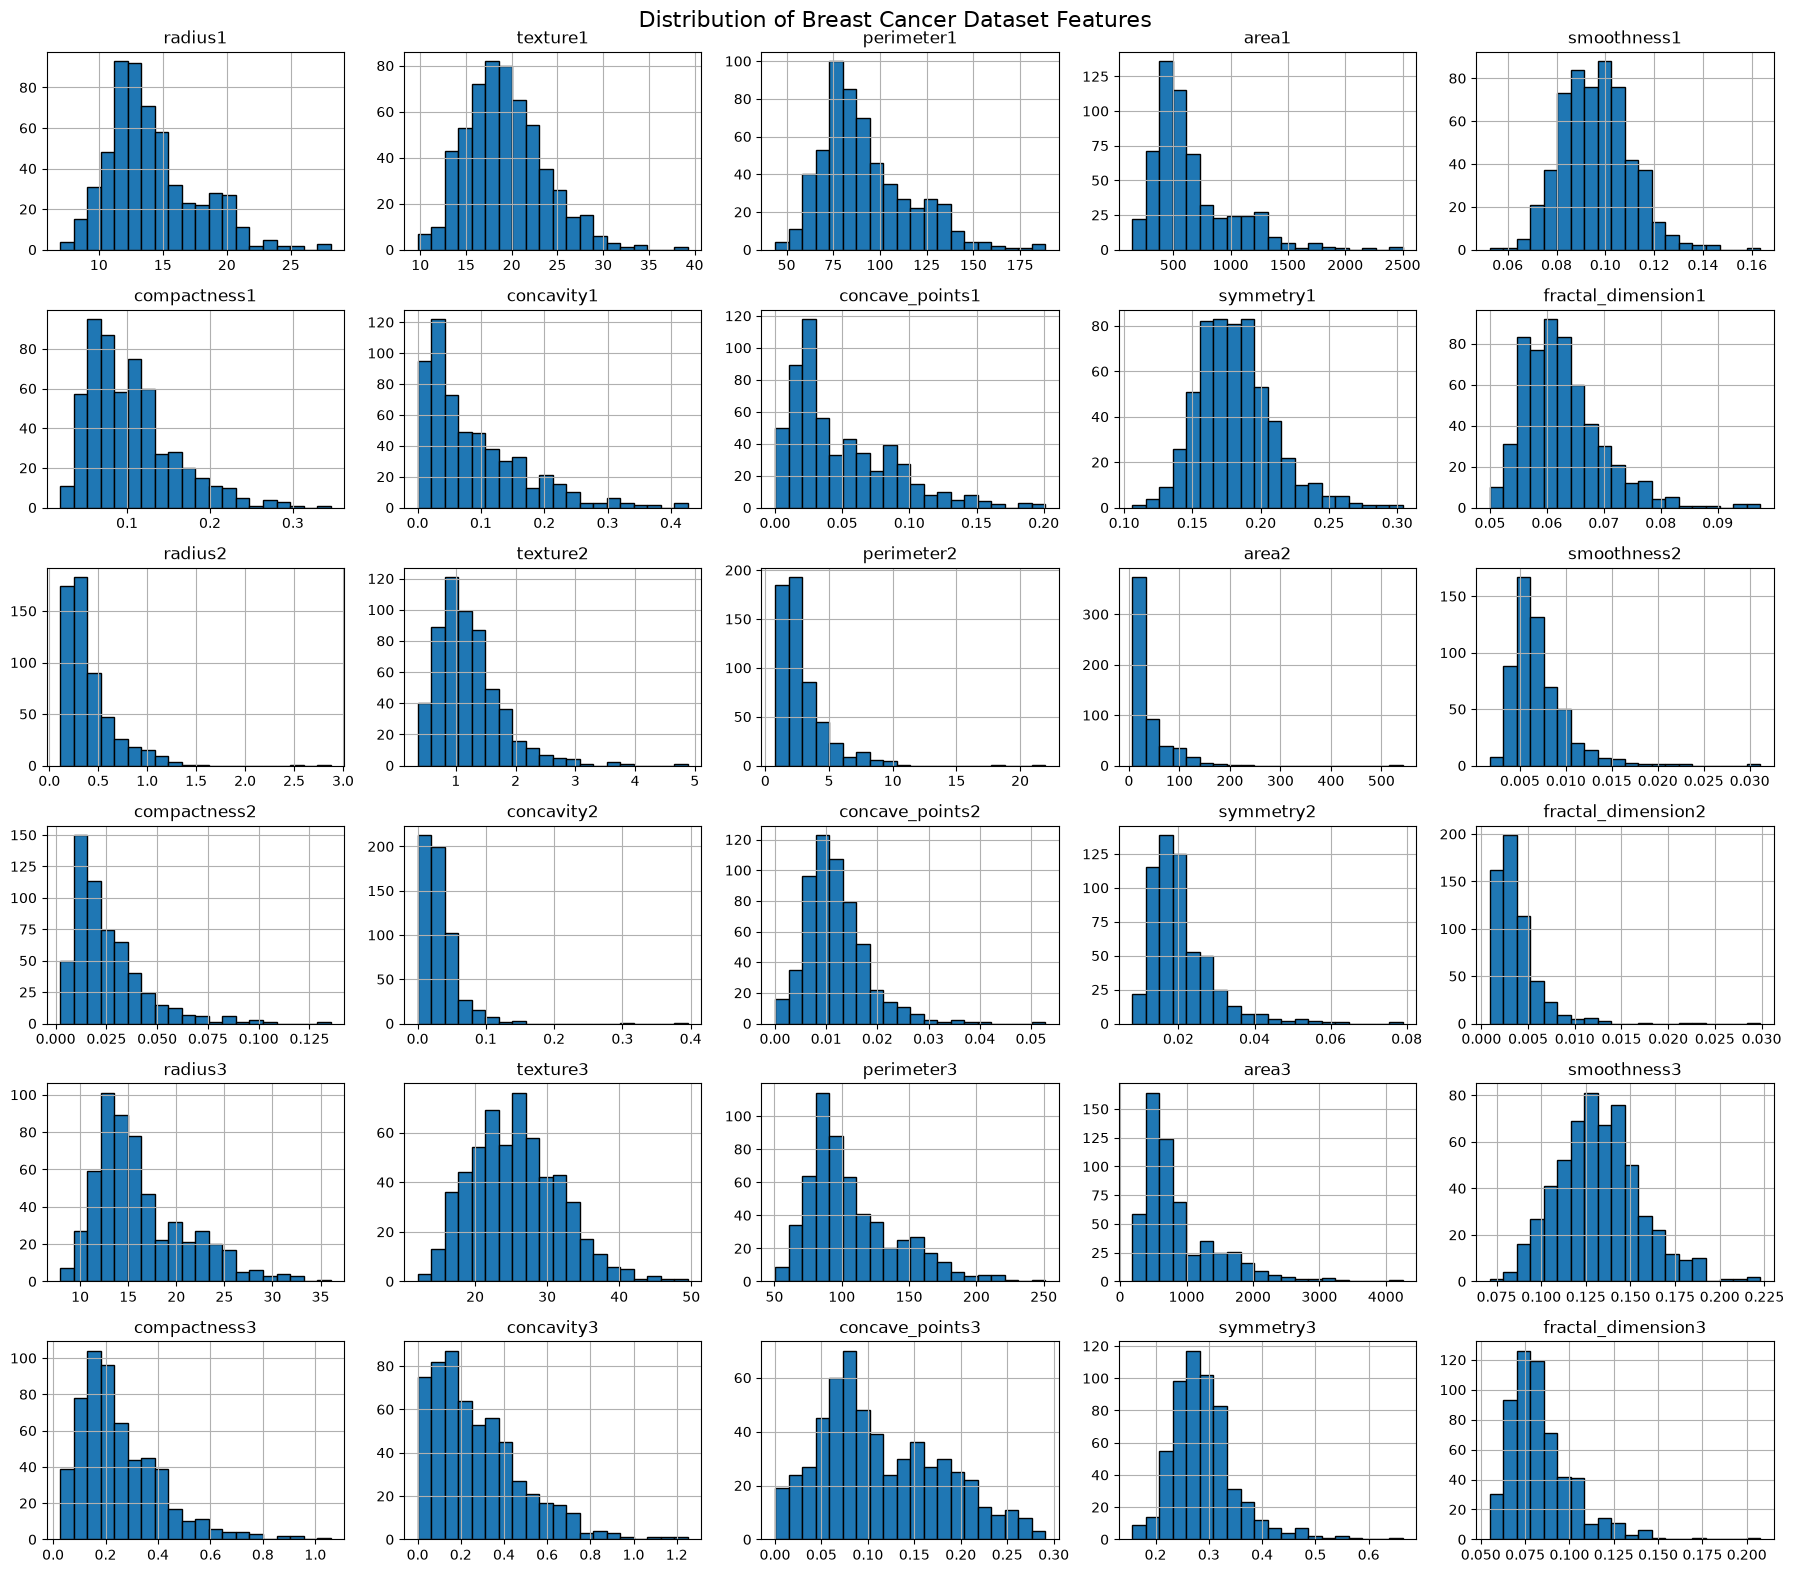

In [14]:
X.hist(
    figsize=(18, 16),
    bins=20,
    edgecolor="black"
)

plt.suptitle(
    "Distribution of Breast Cancer Dataset Features",
    fontsize=16
)

plt.tight_layout()
plt.show()

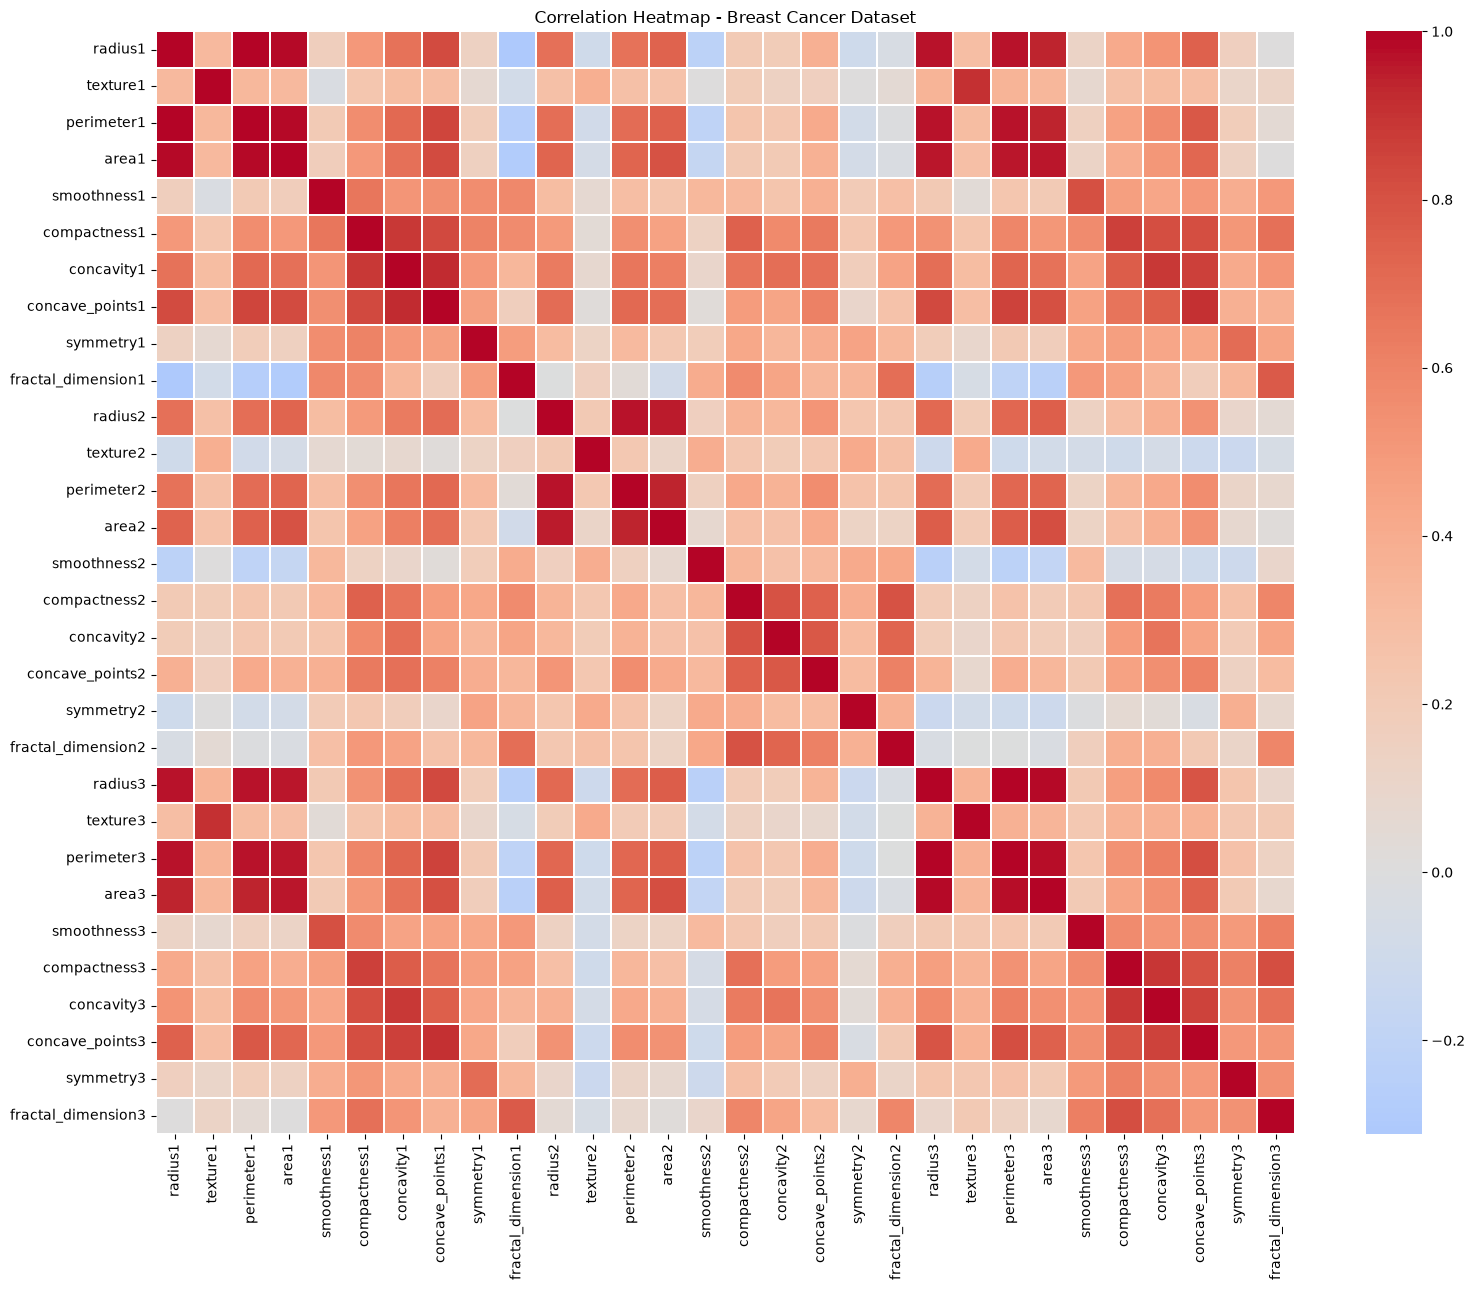

In [15]:
correlation = X.corr()

plt.figure(figsize=(16, 13))

sns.heatmap(
    correlation,
    cmap="coolwarm",
    center=0,
    annot=False,
    linewidths=0.2
)

plt.title("Correlation Heatmap - Breast Cancer Dataset")
plt.tight_layout()
plt.show()

In [16]:
print("========== BREAST CANCER DATASET EDA SUMMARY ==========")

print("Total Records:", df.shape[0])
print("Total Input Features:", X.shape[1])
print("Target Variable:", target_column)
print("Number of Classes:", df[target_column].nunique())
print("Missing Values:", df.isnull().sum().sum())
print("Duplicate Records:", df.duplicated().sum())

print("\nDiagnosis Distribution:")
print(df[target_column].value_counts())

========== BREAST CANCER DATASET EDA SUMMARY ==========
Total Records: 569
Total Input Features: 30
Target Variable: Diagnosis
Number of Classes: 2
Missing Values: 0
Duplicate Records: 0

Diagnosis Distribution:
Diagnosis
B    357
M    212
Name: count, dtype: int64


## EDA Observations

1. The Breast Cancer Wisconsin dataset contains 569 records and 30 input features.
2. The target variable is Diagnosis, with two classes: Benign (B) and Malignant (M).
3. The dataset contains no missing values.
4. No duplicate records were detected.
5. The Benign class contains 357 samples, while the Malignant class contains 212 samples.
6. The dataset has a moderate class imbalance.
7. All 30 input features are numerical and can be used for machine learning after feature scaling.

In [17]:
# Separate input features and target variable

X = df.drop("Diagnosis", axis=1)
y = df["Diagnosis"]

print("Input features shape:", X.shape)
print("Target shape:", y.shape)

print("\nDiagnosis classes:")
print(y.value_counts())

Input features shape: (569, 30)
Target shape: (569,)

Diagnosis classes:
Diagnosis
B    357
M    212
Name: count, dtype: int64


In [18]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining diagnosis distribution:")
print(y_train.value_counts())

print("\nTesting diagnosis distribution:")
print(y_test.value_counts())

Training features: (398, 30)
Testing features: (171, 30)

Training diagnosis distribution:
Diagnosis
B    250
M    148
Name: count, dtype: int64

Testing diagnosis distribution:
Diagnosis
B    107
M     64
Name: count, dtype: int64


In [19]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed successfully!")
print("Scaled training data:", X_train_scaled.shape)
print("Scaled testing data:", X_test_scaled.shape)

Feature scaling completed successfully!
Scaled training data: (398, 30)
Scaled testing data: (171, 30)


In [20]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42
    ),

    "Support Vector Machine": SVC(
        class_weight="balanced"
    )
}

print("Four classification models are ready!")

Four classification models are ready!


In [21]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    precision_score,
    recall_score,
    f1_score
)

results = []
trained_models = {}

for name, model in models.items():

    # Train model
    model.fit(X_train_scaled, y_train)

    # Predict test data
    y_pred = model.predict(X_test_scaled)

    # Calculate metrics
    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test, y_pred,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        y_test, y_pred,
        average="macro",
        zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred,
        average="macro",
        zero_division=0
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

    trained_models[name] = model

    print("\n" + "=" * 50)
    print(name)
    print("=" * 50)

    print(classification_report(
        y_test,
        y_pred,
        labels=["B", "M"],
        target_names=["Benign", "Malignant"],
        zero_division=0
    ))


Logistic Regression
              precision    recall  f1-score   support

      Benign       0.97      0.99      0.98       107
   Malignant       0.98      0.95      0.97        64

    accuracy                           0.98       171
   macro avg       0.98      0.97      0.97       171
weighted avg       0.98      0.98      0.98       171


Decision Tree
              precision    recall  f1-score   support

      Benign       0.91      0.94      0.93       107
   Malignant       0.90      0.84      0.87        64

    accuracy                           0.91       171
   macro avg       0.90      0.89      0.90       171
weighted avg       0.91      0.91      0.91       171


Random Forest
              precision    recall  f1-score   support

      Benign       0.96      1.00      0.98       107
   Malignant       1.00      0.92      0.96        64

    accuracy                           0.97       171
   macro avg       0.98      0.96      0.97       171
weighted avg       0.97

In [22]:
results_df = pd.DataFrame(results)

print("BREAST CANCER MODEL PERFORMANCE COMPARISON")

display(
    results_df.style.format({
        "Accuracy": "{:.2%}",
        "Precision": "{:.2%}",
        "Recall": "{:.2%}",
        "F1 Score": "{:.2%}"
    })
)

BREAST CANCER MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,97.66%,97.82%,97.19%,97.49%
1,Decision Tree,90.64%,90.50%,89.38%,89.88%
2,Random Forest,97.08%,97.77%,96.09%,96.83%
3,Support Vector Machine,98.25%,98.28%,97.97%,98.12%


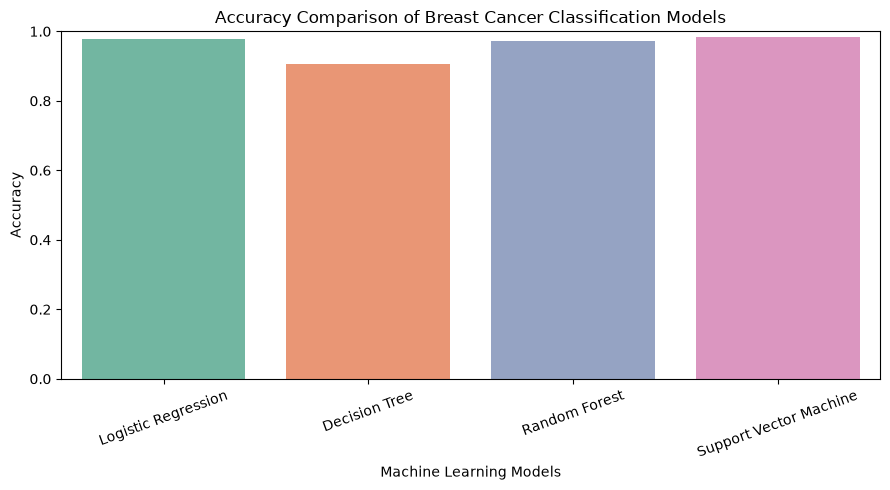

In [23]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="Accuracy",
    hue="Model",
    palette="Set2",
    legend=False
)

plt.title("Accuracy Comparison of Breast Cancer Classification Models")
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

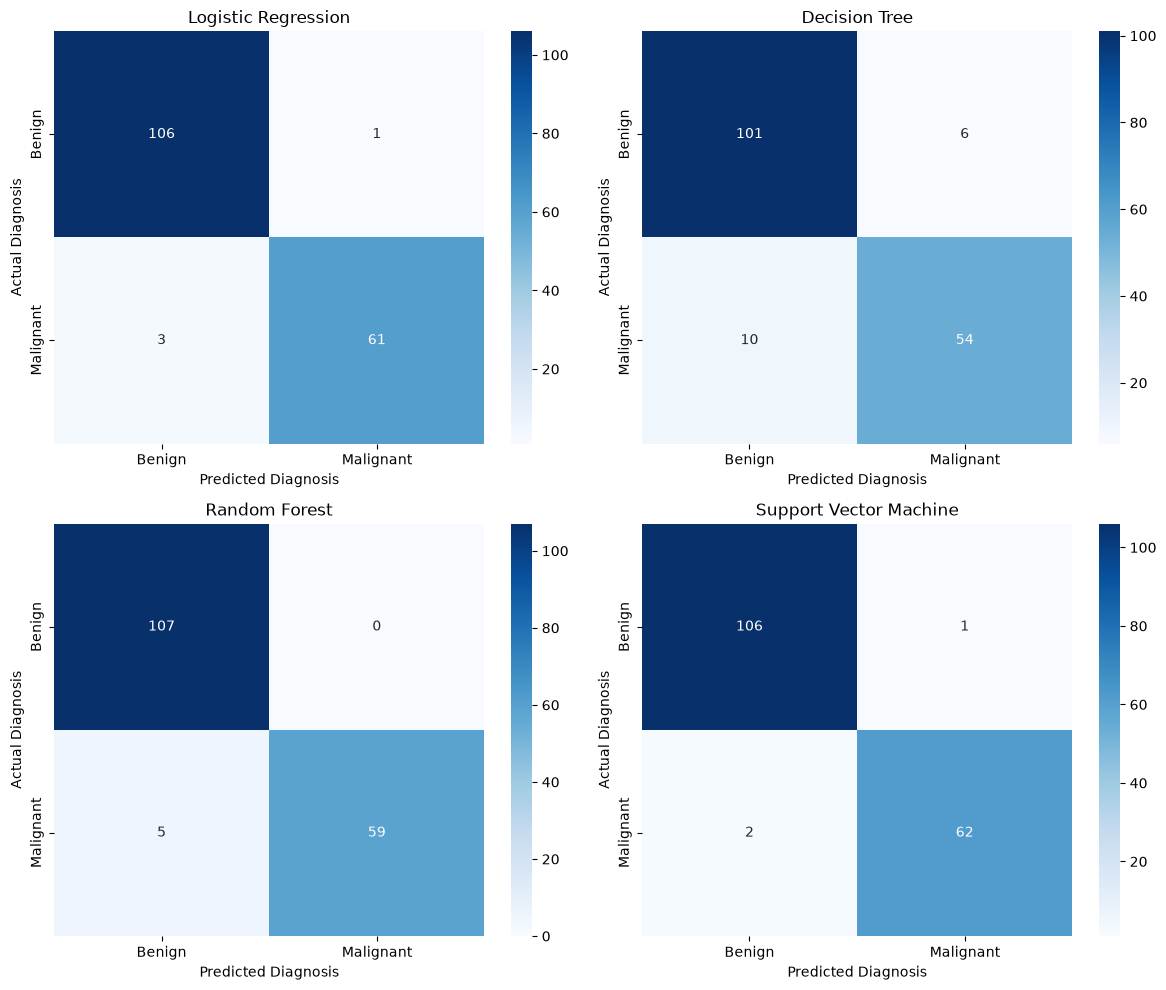

In [24]:
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

class_labels = ["B", "M"]

for ax, (name, model) in zip(axes, trained_models.items()):

    y_pred = model.predict(X_test_scaled)

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=class_labels
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Benign", "Malignant"],
        yticklabels=["Benign", "Malignant"],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Diagnosis")
    ax.set_ylabel("Actual Diagnosis")

plt.tight_layout()
plt.show()

In [25]:
results_df.to_csv(
    "../results/breast_cancer_model_comparison.csv",
    index=False
)

print("Breast Cancer model comparison results saved successfully!")

Breast Cancer model comparison results saved successfully!


# Conclusion

The UCI Breast Cancer Wisconsin (Diagnostic) dataset was
successfully analyzed using Exploratory Data Analysis (EDA),
data preprocessing and machine learning classification
techniques.

The dataset contains 569 records and 30 numerical input
features. The target variable is Diagnosis, which consists
of two classes: Benign (B) and Malignant (M).

The dataset contained no missing values and no duplicate
records. The input features were standardized using
StandardScaler.

The dataset was divided into 70% training data and 30%
testing data using stratified sampling.

Four classification algorithms were implemented:
1. Logistic Regression
2. Decision Tree
3. Random Forest
4. Support Vector Machine (SVM)

Among the four models, Support Vector Machine achieved
the highest accuracy of 98.25%, macro precision of 98.28%,
macro recall of 97.97% and macro F1-score of 98.12%.

Therefore, SVM was the best-performing model in this
experiment.

The results demonstrate that machine learning algorithms
can classify the two diagnosis categories with high
performance on this dataset.

However, these results are based on one train-test split
and should be further validated using cross-validation
and independent data.

This experiment is intended for academic machine learning
purposes and is not a clinically validated diagnostic
system.